# ETF-Datencheck für das Stiftungsprojekt

Dieses Notebook lädt historische ETF-Kurse direkt über die Yahoo-Schnittstellen
mit `yfinance`. Es prüft Datenabdeckung, Handelswährung und Lücken und zeigt
Tagesrenditen sowie die Entwicklung der **einzelnen ETFs** ab Startwert 1.
Es enthält noch keine Portfolio-Gewichtung, Rebalancing-Regel oder Förderauszahlungen.

**Google Colab:** Datei hochladen und **Laufzeit > Alle ausführen** wählen.
Die erste Zelle installiert bei Bedarf die hier verwendeten Bibliotheksversionen.
Eine Internetverbindung ist erforderlich. Yahoo kann Abrufe zeitweise begrenzen.


In [1]:
import importlib.metadata
import subprocess
import sys

requirements = ['yfinance==1.8.0', 'pandas==3.0.1', 'matplotlib==3.11.2']
missing = []
for requirement in requirements:
    package, wanted = requirement.split("==")
    try:
        installed = importlib.metadata.version(package)
    except importlib.metadata.PackageNotFoundError:
        installed = None
    if installed != wanted:
        missing.append(requirement)
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])
print("Verwendete Versionen:", ", ".join(requirements))


Verwendete Versionen: yfinance==1.8.0, pandas==3.0.1, matplotlib==3.11.2


## 1. Instrumente und Zeitraum

Die angefragte Periode beginnt am 1. März 2019 und endet am 31. Oktober 2026.
`end` ist bei yfinance exklusiv. Die tatsächlich gelieferten Daten werden separat
ausgewiesen. Alle ausgewählten Börsenlinien sollen in EUR handeln.

Die EUR-Handelswährung eines globalen Aktien-ETF beseitigt seine zugrunde liegenden
Fremdwährungsrisiken nicht. Der konventionelle Aktienfonds dient als Aktienvergleich;
er ist alleine noch keine Benchmark für ein gemischtes Aktien-Anleihen-Portfolio.


In [2]:
from pathlib import Path
import json
import time
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf
from IPython.display import display

ASSETS = {
    "2B7K.DE": "Nachhaltige Aktien",
    "SUOE.L": "Nachhaltige Euro-Anleihen",
    "EUNL.DE": "Konventionelle Aktien (Vergleich)",
}
START = "2019-03-01"
END = "2026-11-01"
OUTPUT = Path("output")
OUTPUT.mkdir(exist_ok=True)
CACHE = Path("tmp") / "yfinance_cache"
CACHE.mkdir(parents=True, exist_ok=True)
yf.set_tz_cache_location(str(CACHE))


## 2. API-Abruf und Qualitätsprüfung

`auto_adjust=True` berücksichtigt die vom Datenanbieter gemeldeten
Ausschüttungs- und Splitanpassungen. Ausschüttungen dürfen dann nicht nochmals
zur Rendite addiert werden. Die Darstellung entspricht näherungsweise einer
Wiederanlage der Ausschüttungen, ohne individuelle Steuern und Transaktionskosten.

Fehlende Kurse werden nicht vorwärts aufgefüllt. Für den Vergleich werden nur
gemeinsame Beobachtungstage verwendet; ausgeschlossene Tage werden ausgewiesen.
Diese Lückenprüfung erkennt keine fehlerhaften oder veralteten Einzelkurse.


In [3]:
series = {}
records = []
for ticker, name in ASSETS.items():
    print("Lade", ticker, "-", name, flush=True)
    history = None
    last_error = None
    for attempt in range(3):
        try:
            instrument = yf.Ticker(ticker)
            history = instrument.history(
                start=START, end=END, interval="1d",
                auto_adjust=True, actions=True,
            )
            if history is None or history.empty:
                raise ValueError("Leere Antwort vom Datenanbieter")
            break
        except Exception as exc:
            last_error = exc
            if attempt < 2:
                time.sleep(2)
    if history is None or history.empty:
        raise RuntimeError(f"Abruf für {ticker} fehlgeschlagen: {last_error}")
    currency = instrument.get_history_metadata().get("currency")
    if currency != "EUR":
        raise ValueError(f"{ticker}: Handelswährung {currency!r}; EUR erwartet")
    close = history["Close"].copy()
    close.index = pd.DatetimeIndex(close.index).tz_localize(None).normalize()
    if close.index.has_duplicates or close.dropna().le(0).any():
        raise ValueError(f"Ungültige oder doppelte Kurse für {ticker}")
    series[ticker] = close
    records.append({
        "Ticker": ticker, "Bezeichnung": name, "Währung": currency,
        "Erster Kurs": str(close.first_valid_index().date()),
        "Letzter Kurs": str(close.last_valid_index().date()),
        "Kursbeobachtungen": int(close.notna().sum()),
    })

prices = pd.concat(series, axis=1).sort_index()
quality = pd.DataFrame(records).set_index("Ticker")
quality["Lücken im gemeinsamen Tagesraster"] = prices.isna().sum()
display(quality)

common_prices = prices.dropna()
if len(common_prices) < 100:
    raise ValueError("Zu wenige gemeinsame Kurstage für die weitere Analyse")
excluded = len(prices) - len(common_prices)
print(f"Gemeinsamer Zeitraum: {common_prices.index.min().date()} bis "
      f"{common_prices.index.max().date()}")
print(f"Gemeinsame Kurstage: {len(common_prices):,}")
print(f"Wegen fehlender Kurse ausgeschlossene Tage: {excluded}")
display(common_prices.head())
display(common_prices.tail())


Lade 2B7K.DE - Nachhaltige Aktien


Lade SUOE.L - Nachhaltige Euro-Anleihen


Lade EUNL.DE - Konventionelle Aktien (Vergleich)


C:\Users\nilsc\AppData\Local\Temp\ipykernel_44172\779268541.py:38: Pandas4Warning: Sorting by default when concatenating all DatetimeIndex is deprecated.  In the future, pandas will respect the default of `sort=False`. Specify `sort=True` or `sort=False` to silence this message. If you see this warnings when not directly calling concat, report a bug to pandas.
  prices = pd.concat(series, axis=1).sort_index()


,Bezeichnung,Währung,Erster Kurs,Letzter Kurs,Kursbeobachtungen,Lücken im gemeinsamen Tagesraster
Ticker,,,,,,
2B7K.DE,Nachhaltige Aktien,EUR,2019-03-01,2026-10-30,1948,21
SUOE.L,Nachhaltige Euro-Anleihen,EUR,2019-03-01,2026-10-30,1937,32
EUNL.DE,Konventionelle Aktien (Vergleich),EUR,2019-03-01,2026-10-30,1948,21


Gemeinsamer Zeitraum: 2019-03-01 bis 2026-10-30
Gemeinsame Kurstage: 1,916
Wegen fehlender Kurse ausgeschlossene Tage: 53


,2B7K.DE,SUOE.L,EUNL.DE
Date,,,
2019-03-01,5.603,4.353828,48.394001
2019-03-04,5.626,4.358996,48.631001
2019-03-05,5.636,4.355549,48.736000
2019-03-06,5.608,4.358135,48.518002
2019-03-07,5.608,4.365025,48.487999


,2B7K.DE,SUOE.L,EUNL.DE
Date,,,
2026-10-26,14.322,4.539142,130.470001
2026-10-27,14.456,4.546516,131.604996
2026-10-28,14.456,4.548729,131.720001
2026-10-29,14.456,4.561759,131.460007
2026-10-30,14.308,4.565200,129.684998


## 3. Renditen und ETF-Vergleich

Die Renditen beziehen sich auf aufeinanderfolgende gemeinsame Beobachtungstage.
Wenn ein Börsenplatz geschlossen war, kann eine Beobachtung mehrere Kalendertage
umfassen. Die Kurven vergleichen unterschiedliche Anlageklassen und stellen keine
Risikogleichheit oder fertige Portfoliostrategie dar.


,2B7K.DE,SUOE.L,EUNL.DE
Date,,,
2019-03-04,0.004105,0.001187,0.004897
2019-03-05,0.001778,-0.000791,0.002159
2019-03-06,-0.004968,0.000594,-0.004473
2019-03-07,0.000000,0.001581,-0.000618
2019-03-08,0.000000,-0.002171,-0.010539


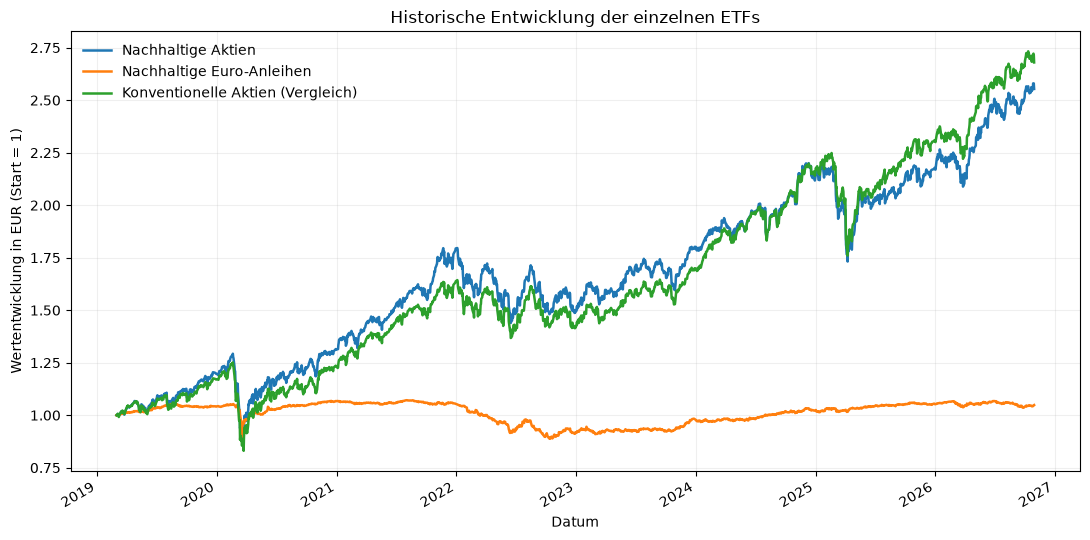

Abruf und Datencheck abgeschlossen.


In [4]:
returns = common_prices.pct_change(fill_method=None).dropna()
normalized = common_prices.div(common_prices.iloc[0])
display(returns.head())

fig, ax = plt.subplots(figsize=(11, 5.5))
normalized.rename(columns=ASSETS).plot(ax=ax, linewidth=1.8)
ax.set_title("Historische Entwicklung der einzelnen ETFs")
ax.set_xlabel("Datum")
ax.set_ylabel("Wertentwicklung in EUR (Start = 1)")
ax.grid(alpha=0.2)
ax.legend(loc="upper left", frameon=False)
fig.tight_layout()
fig.savefig(OUTPUT / "etf_vergleich.png", dpi=160)
plt.show()

summary = {
    "source": "Yahoo Finance via yfinance",
    "retrieved_at_utc": pd.Timestamp.now(tz="UTC").isoformat(),
    "requested_start": START, "requested_end_exclusive": END,
    "common_start": str(common_prices.index.min().date()),
    "common_end": str(common_prices.index.max().date()),
    "common_price_rows": len(common_prices),
    "return_rows": len(returns),
    "excluded_union_days": excluded,
    "instruments": quality.reset_index().to_dict(orient="records"),
    "versions": {p: importlib.metadata.version(p)
                 for p in ("yfinance", "pandas", "matplotlib")},
}
(OUTPUT / "datencheck_ergebnis.json").write_text(
    json.dumps(summary, ensure_ascii=False, indent=2), encoding="utf-8"
)
print("Abruf und Datencheck abgeschlossen.")


## Quellen und Grenzen

- [Nachhaltiger Aktienfonds: iShares MSCI World SRI](https://www.ishares.com/de/privatanleger/de/produkte/290846/ishares-msci-world-sri-ucits-etf-2b7k)
- [Nachhaltiger Anleihenfonds: iShares Euro Corp Bond ESG SRI](https://www.ishares.com/uk/professionals/en/products/297933/ishares-corp-bond-esg-sri-ucits-etf-suoe)
- [Aktienvergleich: iShares Core MSCI World](https://www.ishares.com/de/privatanleger/de/produkte/251882/ishares-core-msci-world-ucits-etf-eunl)
- [yfinance-Dokumentation](https://ranaroussi.github.io/yfinance/)

Yahoo-Daten können korrigiert werden; spätere Abrufe können deshalb abweichen.
Die Wahl heute verfügbarer Fonds kann Auswahl- und Survivorship-Bias enthalten.
Die heutigen Nachhaltigkeitsregeln belegen nicht automatisch unveränderte Kriterien
über den gesamten historischen Zeitraum. Für den Prospekt müssen Methodikänderungen
und relevante historische Kriterien gesondert geprüft werden.

**Nächster Modellschritt:** Das Anlagemandat begründen, daraus Gewichtungen und eine
Rebalancing-Regel ableiten und anschließend Portfolio und passende Benchmark berechnen.

**KI-Nutzung:** Dieses Notebook wurde mit OpenAI Codex erstellt und ausgeführt.
Die Gruppe muss Daten, Code und Schlussfolgerungen selbst prüfen und die KI-Nutzung
gemäß Aufgabenstellung offenlegen. Die Instrumente sind Untersuchungskandidaten.
